# Modelagem: LOS de UTI na coorte de insuficiência cardíaca

Regressão do tempo de UTI em dias (`los_dias`), usando só o painel das primeiras 24 horas. O CID não entra no modelo.

Modelos treinados em `modelagem_los_uti_ic.py`:

- **Ridge** e **Lasso** na matriz escalonada (baseline linear). O alpha foi escolhido com validação cruzada por paciente, só no treino.
- **Random Forest** e **XGBoost** na matriz sem escala.
- Referência: prever, para todo mundo, a **mediana do LOS no treino**.

Métricas no conjunto de teste: MAE, RMSE e R². SHAP no XGBoost (2.000 estadias do teste).


In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ARTEFATOS = Path("artefatos")
metricas = pd.read_csv(ARTEFATOS / "metricas_modelos.csv")
shap_imp = pd.read_csv(ARTEFATOS / "shap_xgboost.csv")

print("Teste (quanto menor MAE e RMSE, melhor; quanto maior R2, melhor)")
display(metricas[metricas["conjunto"] == "teste"].sort_values("MAE"))
print("Treino (só para ver sobreajuste)")
display(metricas[metricas["conjunto"] == "treino"].sort_values("MAE"))


Teste (quanto menor MAE e RMSE, melhor; quanto maior R2, melhor)


              modelo conjunto       MAE      RMSE        R2
0            XGBoost    teste  2.667078  5.661657  0.024586
1      Random Forest    teste  2.675554  5.727971  0.001603
2              Ridge    teste  2.715745  5.762128 -0.010340
3              Lasso    teste  2.717032  5.765141 -0.011397
4  Mediana do treino    teste  2.762472  5.986036 -0.090386

Treino (só para ver sobreajuste)


              modelo conjunto       MAE      RMSE        R2
5            XGBoost   treino  2.275932  4.892966  0.220296
6      Random Forest   treino  2.458344  5.268346  0.096072
7              Ridge   treino  2.738093  5.589751 -0.017584
8              Lasso   treino  2.740587  5.593486 -0.018944
9  Mediana do treino   treino  2.781155  5.816233 -0.101714

## Como ler

No **teste**, a mediana do treino tem o menor MAE (cerca de 2,76 dias). Random Forest e XGBoost ficam perto de 3,02 dias.

No **RMSE** e no **R²**, o Random Forest fica na frente (RMSE cerca de 5,56 dias, R² cerca de 0,06), com o XGBoost logo atrás. Ridge e Lasso explicam quase a mesma fração, um pouco menos.

O R² no teste é baixo: o painel das primeiras 24 horas explica pouco do tempo total de UTI. O LOS é assimétrico (muitos ficam cerca de 2 dias; alguns ficam semanas), então errar as estadias longas pesa no RMSE.

O XGBoost sobe de R² 0,41 no treino para 0,05 no teste. Ele decorou parte do treino. O número que vale para o TCC é o do teste.


SHAP do XGBoost: contribuição média absoluta, em dias de UTI


                       variavel  shap_medio_abs
0                      spo2_24h        0.067533
1                         idade        0.060487
2                       ptt_24h        0.058242
3                       pam_24h        0.054081
4                   glicose_24h        0.050215
5   frequencia_respiratoria_24h        0.042840
6       frequencia_cardiaca_24h        0.042001
7                     ureia_24h        0.032746
8                     sodio_24h        0.028846
9                creatinina_24h        0.027773
10                 feve_ausente        0.024860
11         tipo_admissao_URGENT        0.024556

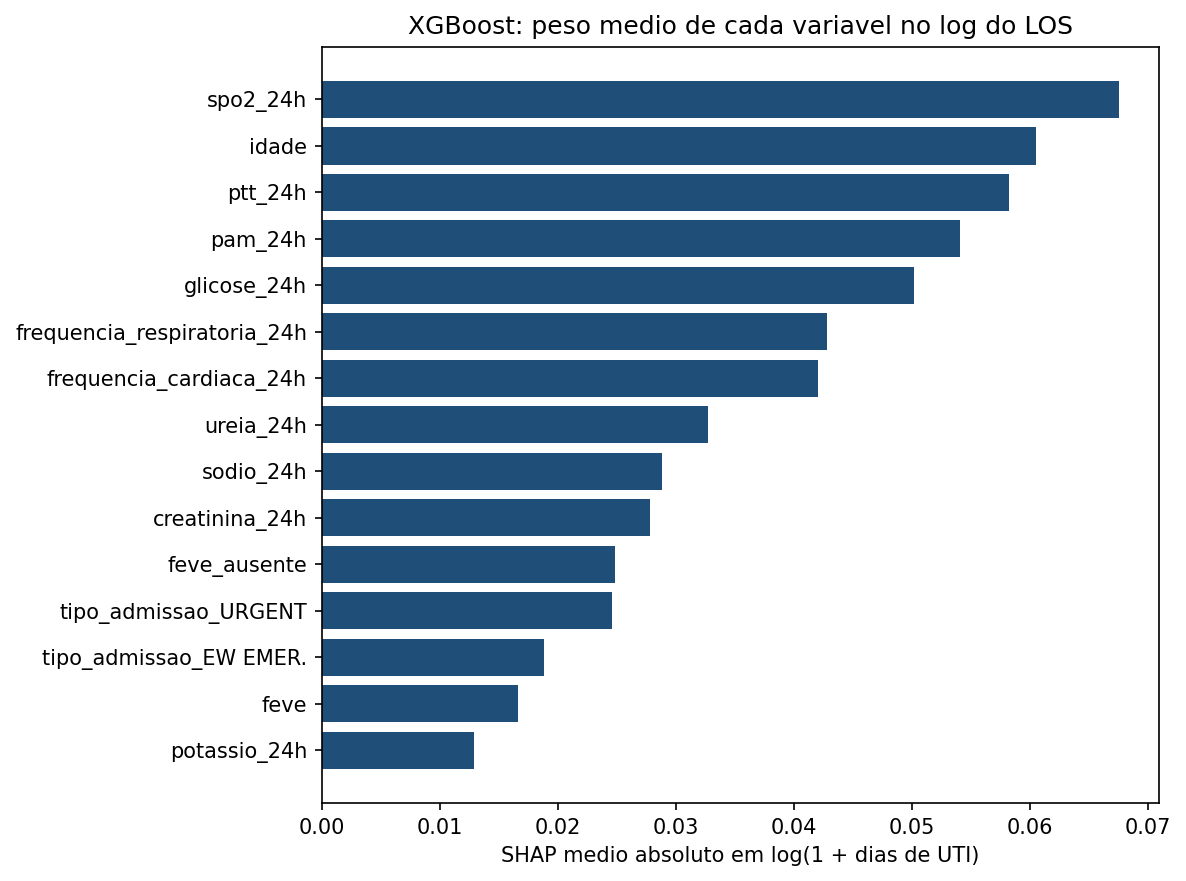

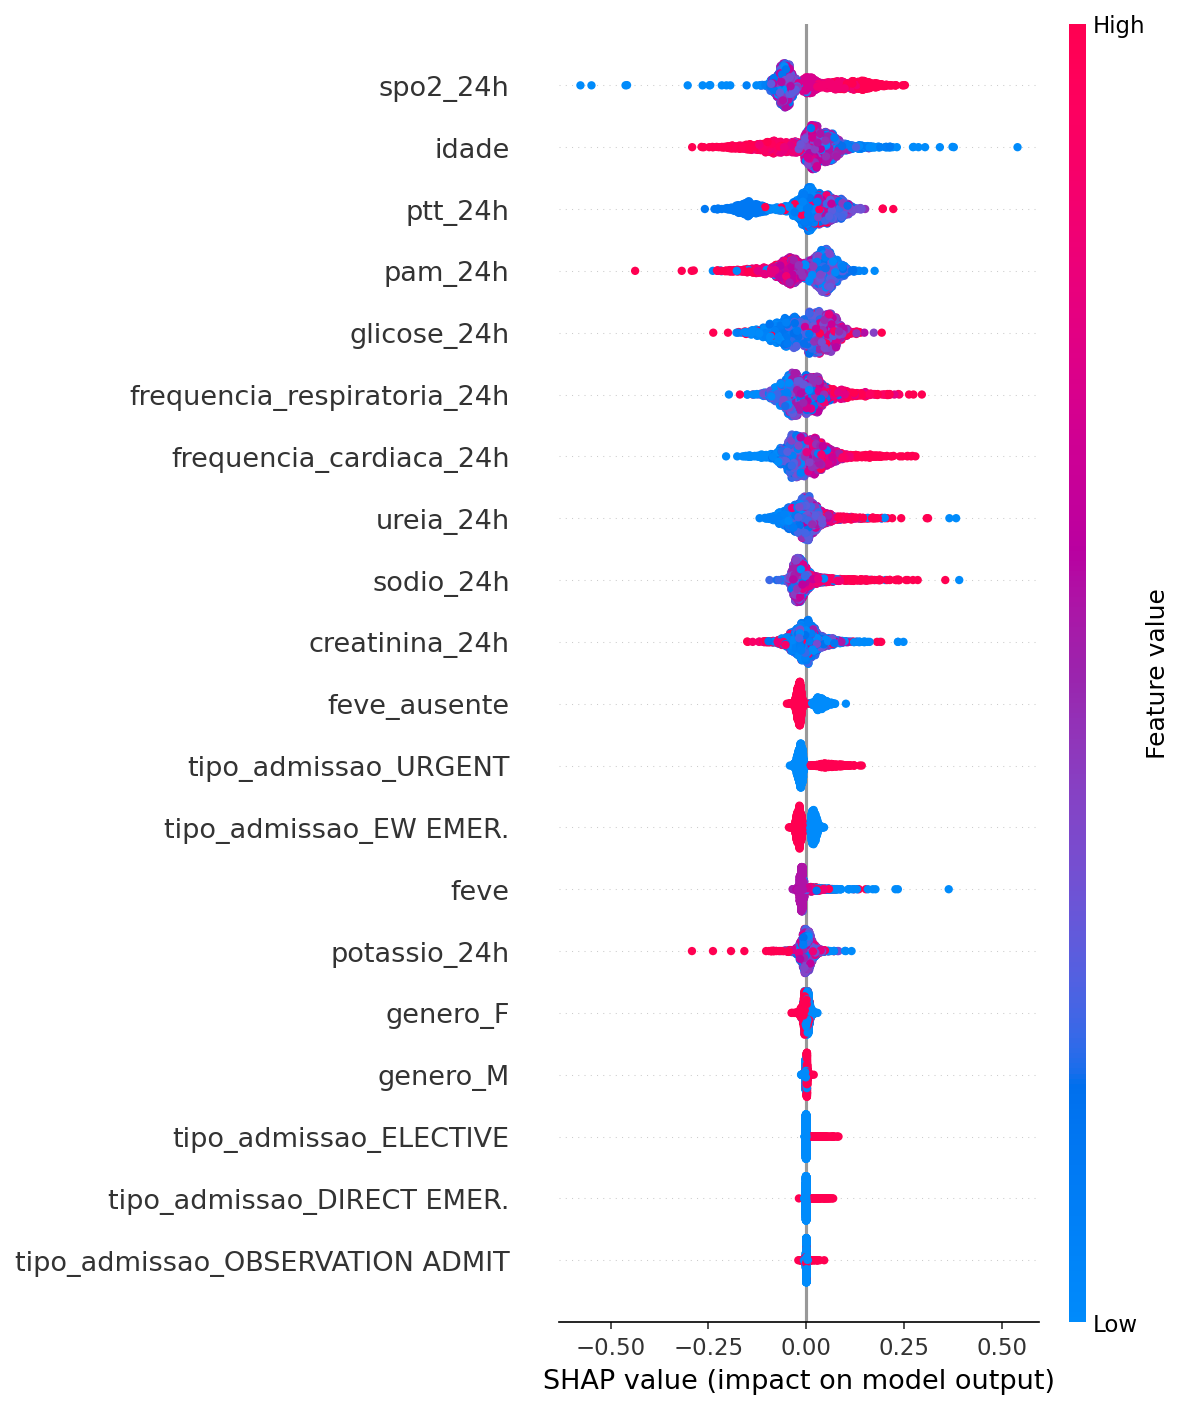

In [3]:
print("SHAP do XGBoost: contribuição média absoluta, em dias de UTI")
display(shap_imp.head(12))
display(Image(filename=str(ARTEFATOS / "figuras" / "shap_xgboost_barras.png")))
display(Image(filename=str(ARTEFATOS / "figuras" / "shap_xgboost_beeswarm.png")))


## SHAP

No gráfico de barras, a barra é o peso médio da variável na predição do XGBoost. As maiores são idade, saturação, frequência respiratória, TTPA, glicose e pressão arterial média.

No beeswarm, cada ponto é uma estadia do teste. Cor mais alta significa valor maior da variável. A posição no eixo mostra se aquele valor empurrou o LOS previsto para cima ou para baixo.

A FEVE aparece, mas com peso menor do que idade e os sinais vitais. Em parte porque falta em cerca de 65% da coorte.

Para treinar de novo: `python modelagem_los_uti_ic.py`.
